# Project 2

### Task b)

In [1]:
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import scipy.stats as stats
from scipy.stats import t
import pandas as pd


In [105]:
birth_rate = 5 / 60 #in minutes
death_rate = 1/10 #minutes
inv_mu = 10

prob_jump_forward = birth_rate/(birth_rate + death_rate)

X0 = 0

#Function for simlating the birth adn death process
def simulate_bdp(B):
    X_arr = []
    sojourn_times = []
    X = X0
    t = 0

    while (t < B * 24 *60):
        X_arr.append(X)

        #if the state = 0, will always make a jump forward in time when the sojourntime is over
        if X == 0:
            s = np.random.exponential(1/(birth_rate)) #here the death rate is zero
            t += s
            X += 1
            sojourn_times.append(s)

        else:
            s = np.random.exponential(1/(death_rate + birth_rate))
            t += s
            sojourn_times.append(s)

            #taking a jump either forwards or backwards
            u_ = np.random.uniform(0, 1)
            if u_ < prob_jump_forward:
                X += 1

            else:
                X -= 1

    
    sojourn_times[-1] = B*24*60 - np.sum(sojourn_times[:-1])
        
        
    return X_arr,sojourn_times

X, s = simulate_bdp(50)

print(X)
print(s)


[0, 1, 2, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 3, 4, 5, 6, 5, 4, 3, 4, 3, 4, 3, 2, 3, 2, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 2, 3, 4, 3, 4, 5, 4, 3, 2, 3, 4, 3, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 2, 3, 2, 3, 4, 3, 2, 1, 0, 1, 2, 1, 0, 1, 2, 1, 2, 3, 2, 1, 2, 3, 4, 5, 6, 5, 6, 7, 6, 7, 6, 5, 6, 5, 4, 5, 4, 3, 4, 3, 4, 3, 2, 1, 2, 1, 2, 3, 2, 1, 0, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 2, 3, 4, 5, 4, 3, 4, 3, 2, 1, 0, 1, 0, 1, 2, 3, 2, 1, 0, 1, 2, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 3, 4, 3, 4, 3, 4, 3, 2, 3, 2, 3, 4, 3, 2, 1, 0, 1, 2, 3, 4, 3, 4, 3, 4, 3, 2, 3, 2, 3, 2, 3, 2, 3, 4, 5, 4, 5, 6, 5, 6, 7, 8, 9, 8, 9, 8, 9, 8, 7, 8, 9, 8, 9, 10, 9, 10, 9, 10, 9, 8, 7, 8, 9, 8, 7, 8, 7, 6, 7, 8, 9, 8, 7, 8, 7, 6, 7, 6, 5, 4, 5, 4, 5, 6, 5, 6, 5, 4, 3, 4, 5, 6, 5, 4, 3, 2, 3, 2, 1, 0, 1, 2, 1, 2, 3, 2, 1, 0, 1, 0, 1, 0, 1, 2, 1, 2, 1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 13, 14, 15, 16, 15, 14, 15, 16, 15, 16, 17, 18, 17, 16, 17, 18, 17, 18, 17, 18, 19, 18, 

In [116]:
#Estimate of long-run mean number of patients in the UCC
def long_run_mean(B):
    X_arr, s_times = simulate_bdp(B)
    weighted_states = np.sum(np.array(X_arr[int(len(X_arr)/2):])*np.array(s_times[int(len(s_times)/2):]))
    X_weighted = weighted_states/np.sum(np.array(s_times[int(len(s_times)/2):]))
    
    return X_weighted

def expected_long_rund_mean(sims, B):
    lrm_arr = []
    for i in range(sims):
        lrm_arr.append(long_run_mean(B))

    return np.sum(np.array(lrm_arr))/sims


#Finding the waiting time using Little's Law
def waiting_time_LL(birth_rate, L):
    return L/birth_rate

W = waiting_time_LL(birth_rate, expected_long_rund_mean(30, 50))

print(f"Expected long run mean: ", W)

Expected long run mean:  60.591732268790615


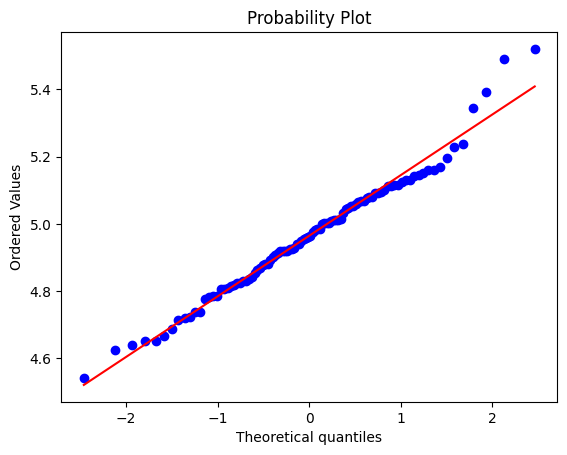

In [ ]:

X_means = []

for i in range(100):
    X_values = []

    for j in range(30):
        X_values.append(long_run_mean(50))

    X_means.append(np.mean(X_values))

# Q-Q plot
stats.probplot(X_means, dist="norm", plot=plt)
plt.show()


In [ ]:
#Reapeat 30 times and compute an approximate 95% CI for the expected time
W_bar_times = []

for j in range(30):
    W_bar_times.append(waiting_time_LL(birth_rate, long_run_mean(50)))

#defining a function for computing CI
def CI(exp_values):  
    n_simulations = len(exp_values) 
    mean = np.mean(exp_values)

    s = np.sqrt(1/(n_simulations-1)*sum((mean-exp_values)**2))
    SE = np.sqrt(s**2/n_simulations)

    #using scipy.stats.t -> a Student's t continuous random variable to get the t-value
    t_value = t.ppf(0.975, df=n_simulations-1)

    lower = mean - t_value*SE
    upper = mean + t_value*SE

    return np.array([lower, upper])

#Computing the CI for the expected waiting time in the UCC
CI_exp_W = CI(W_bar_times)


#Plotting a table for the CI's
ci_df = pd.DataFrame({
    "E[W]" : CI_exp_W},
    index = ["Lower", "Upper"]
    )

display(
    ci_df.style
    .set_caption("95% Confidence Intervals")
    .set_table_styles([
        {
            "selector":"caption",
            "props" : [("font-size", "20px")]
        }
    ])
    .format("{:2f}")
    .set_properties(**{
        "font-size": "16px",
        "min-width": "120px",
        "padding" : "10px"
    })
    .background_gradient(cmap = "tab20b", axis = None)
)


[55.24023922 61.07479034]


,E[W]
Lower,55.240239
Upper,61.074790


In [130]:
#Comparing the CI to the exact value computed in 1a)
W_exact = 60
count = 0

for i in range(1000):
    W_bar_times = []

    for j in range(30):
        W_bar_times.append(waiting_time_LL(birth_rate, long_run_mean(50)))

    CI_exp_W = CI(W_bar_times)

    if W_exact >= CI_exp_W[0] and W_exact <= CI_exp_W[1]:
        count += 1

print(f"Exact value in the CI ", count/1000, "percent of the time")


    

Exact value in the CI  0.945 percent of the time


[0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 2, 3, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 3, 2, 1, 0, 1, 2, 1, 2, 3, 2, 1, 0, 1, 0, 1, 0, 1, 2, 3, 2, 3, 4, 3, 4, 3, 4, 5, 4, 5, 4, 5, 6, 5, 6, 5, 4, 3, 2, 1, 0, 1, 0, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 3, 2, 1, 2, 3, 4, 5, 4, 5, 6, 5, 6, 7, 6, 5, 6, 5, 4, 5, 4, 5, 4, 3, 2, 1, 0]
[5.686108233455228, 2.83555296418783, 27.438070767068425, 2.170741740524444, 20.171093324119102, 4.633110063576259, 5.48638390884239, 0.8734408491101484, 6.516155345436712, 12.015083874946752, 13.077191124703226, 7.623016199834115, 0.13973122583932296, 0.31269512174503405, 2.922574220294618, 1.7842933384115338, 0.5447353428562374, 1.532444672850959, 3.2850834063167778, 17.631975803300737, 4.919242034572841, 11.81774376465517, 25.21800575814357, 0.6259197912712383, 0.2630828834351316, 4.696997374901151, 1.9920555356411613, 6.080636478853211, 7.907224575259255, 4.987748814403995, 1.035870451058879, 5.7185801285397035, 2.3177764372646874, 2.54382208569061

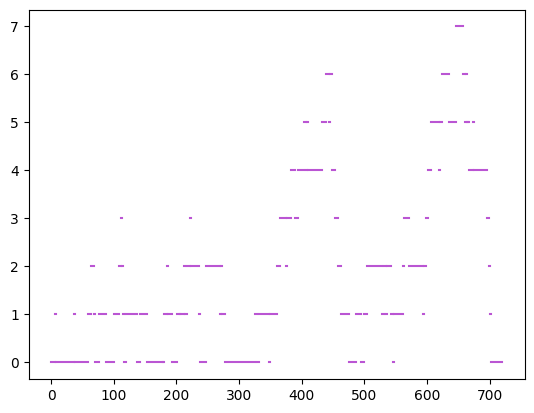

In [114]:
#Plotting one realization of X(t) for the time 0-12 hours

#Simulating BDP for 12 hours
X, sojourn_time = simulate_bdp(0.5)

print(X)
print(sojourn_time)

time = 0

for state, s in zip(X, sojourn_time):
    plt.plot([time, time + s], [state, state], color = 'mediumorchid')
    time += s
    

plt.show()
